In [ ]:
# prompt: wget pipeline

!wget https://www.dropbox.com/s/iyv483wz7ztr9gh/gender_net.caffemodel?dl=0

--2025-06-07 13:42:09--  https://www.dropbox.com/s/iyv483wz7ztr9gh/gender_net.caffemodel?dl=0
Resolving www.dropbox.com (www.dropbox.com)... 162.125.5.18, 2620:100:601d:18::a27d:512
Connecting to www.dropbox.com (www.dropbox.com)|162.125.5.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://www.dropbox.com/scl/fi/j7gcbj1l3ur6r8jdf3k7k/gender_net.caffemodel?rlkey=g7us6rvnw8ji7z64d5zy002h4&dl=0 [following]
--2025-06-07 13:42:10--  https://www.dropbox.com/scl/fi/j7gcbj1l3ur6r8jdf3k7k/gender_net.caffemodel?rlkey=g7us6rvnw8ji7z64d5zy002h4&dl=0
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://uc7882dfdcdf8a098e2829e326e9.dl.dropboxusercontent.com/cd/0/inline/CrI8FjvwkJK5CeaRyxBp8xskl8MOxrSICwE5uHVmC8DgsndypNtO6VyDXF5ic2jbl41fuDYKkhQfxJVXFNDIbD_QRXtfWV0pa_xyZ7cIfoGIt4BK1lJiZjR1G-Fj0RglQiA/file# [following]
--2025-06-07 13:42:10--  https://uc7882dfdcdf8a098e2829e326e9.dl.dropboxusercont

In [ ]:
!wget https://www.dropbox.com/s/xfb20y596869vbb/age_net.caffemodel?dl=0

In [4]:
import cv2
# Model files
AGE_MODEL = "age_net.caffemodel"
AGE_PROTO = "age_deploy.prototxt"
GENDER_MODEL = "gender_net.caffemodel"
GENDER_PROTO = "gender_deploy.prototxt"

# Load models
age_net = cv2.dnn.readNetFromCaffe(AGE_PROTO, AGE_MODEL)
gender_net = cv2.dnn.readNetFromCaffe(GENDER_PROTO, GENDER_MODEL)


In [5]:
AGE_LIST = ['(0-2)', '(4-6)', '(8-12)', '(15-20)',
            '(25-32)', '(38-43)', '(48-53)', '(60-100)']
GENDER_LIST = ['Male', 'Female']

In [45]:
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
face_net = cv2.dnn.readNetFromCaffe("deploy.prototxt",
                                    "res10_300x300_ssd_iter_140000.caffemodel")

def detect_face(frame):
    h, w = frame.shape[:2]
    blob = cv2.dnn.blobFromImage(cv2.resize(frame, (300, 300)),
                                 1.0, (300, 300), (104.0, 177.0, 123.0))
    face_net.setInput(blob)
    detections = face_net.forward()

    faces = []
    for i in range(detections.shape[2]):
        confidence = detections[0, 0, i, 2]
        if confidence > 0.6:
            box = detections[0, 0, i, 3:7] * [w, h, w, h]
            (x1, y1, x2, y2) = box.astype("int")
            faces.append((x1, y1, x2 - x1, y2 - y1))
    return faces


In [46]:
def predict_age_and_gender(face_img):
    blob = cv2.dnn.blobFromImage(face_img, 1.0, (227, 227),
                                 (78.4263377603, 87.7689143744, 114.895847746), swapRB=False)

    gender_net.setInput(blob)
    gender = GENDER_LIST[gender_net.forward().argmax()]

    age_net.setInput(blob)
    age = AGE_LIST[age_net.forward().argmax()]

    return gender, age


In [47]:
from google.colab.patches import cv2_imshow
def predict(file_name,is_image=True):
  if is_image:
    frame=cv2.imread(file_name)
  else :
    frame=file_name
  faces = detect_face(frame)
  for (x, y, w, h) in faces:
        face_img = frame[y:y+h, x:x+w]
        gender, age = predict_age_and_gender(face_img)

        label = f"{gender}, {age}"
        cv2.rectangle(frame, (x, y), (x+w, y+h), (255, 255, 0), 2)
        cv2.putText(frame, label, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX,
                    0.8, (0, 255, 255), 2, cv2.LINE_AA)

  cv2_imshow(frame)

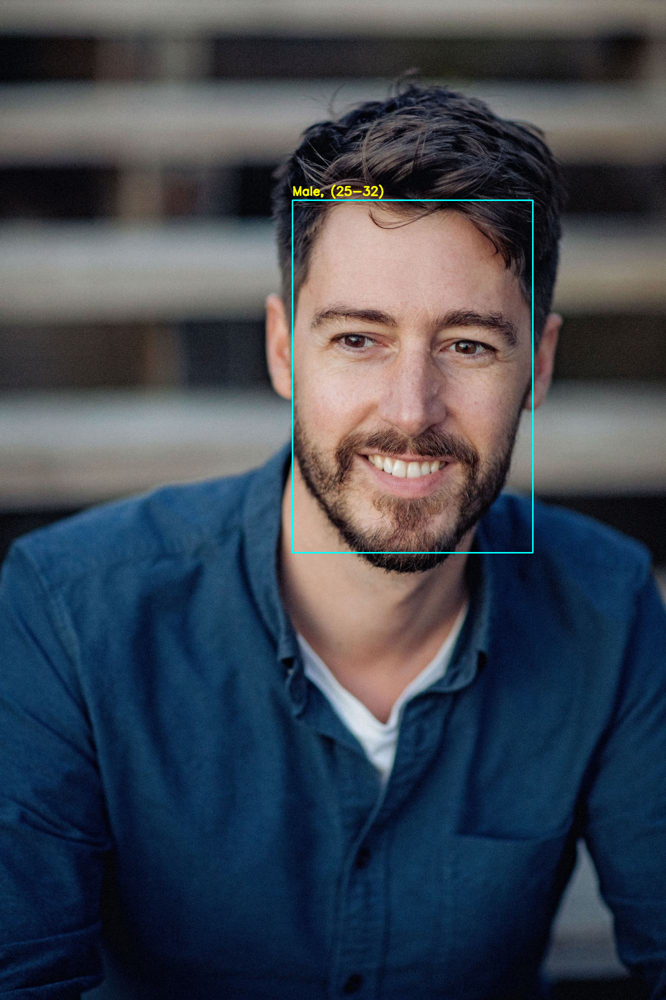

In [48]:
predict('/content/guybolton-photo-deadline.jpg')

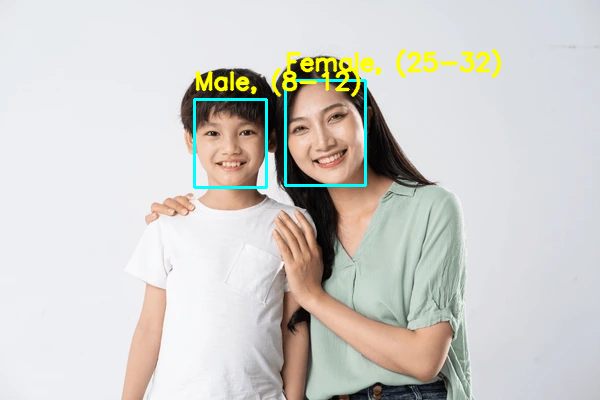

In [49]:
predict("/content/mother-son-posing-on-white-600nw-2344660143.webp")

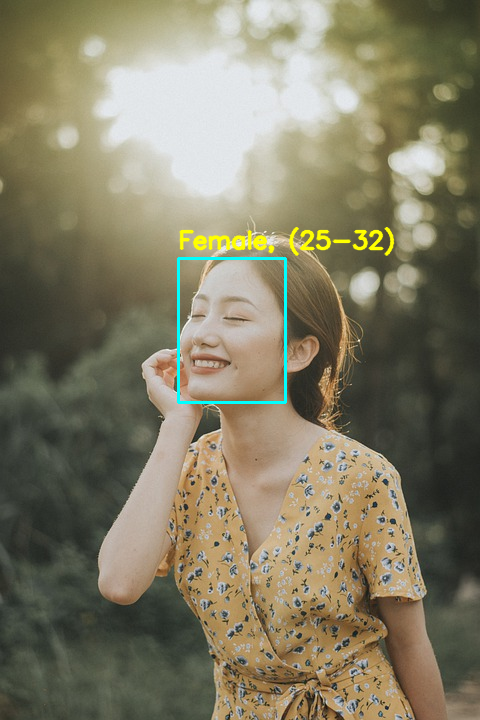

In [50]:
predict("girl1.jpg")

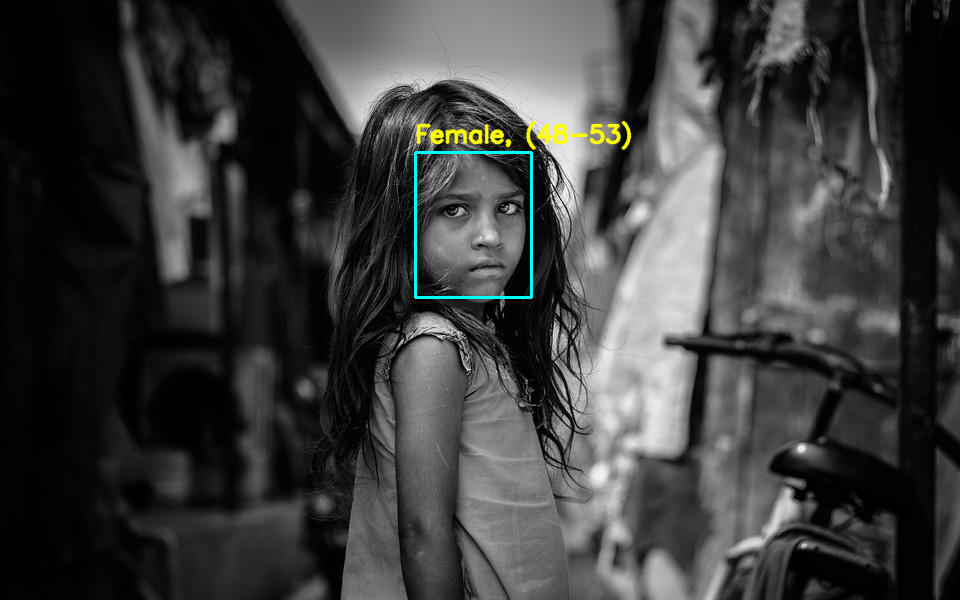

In [51]:
predict("girl2.jpg")

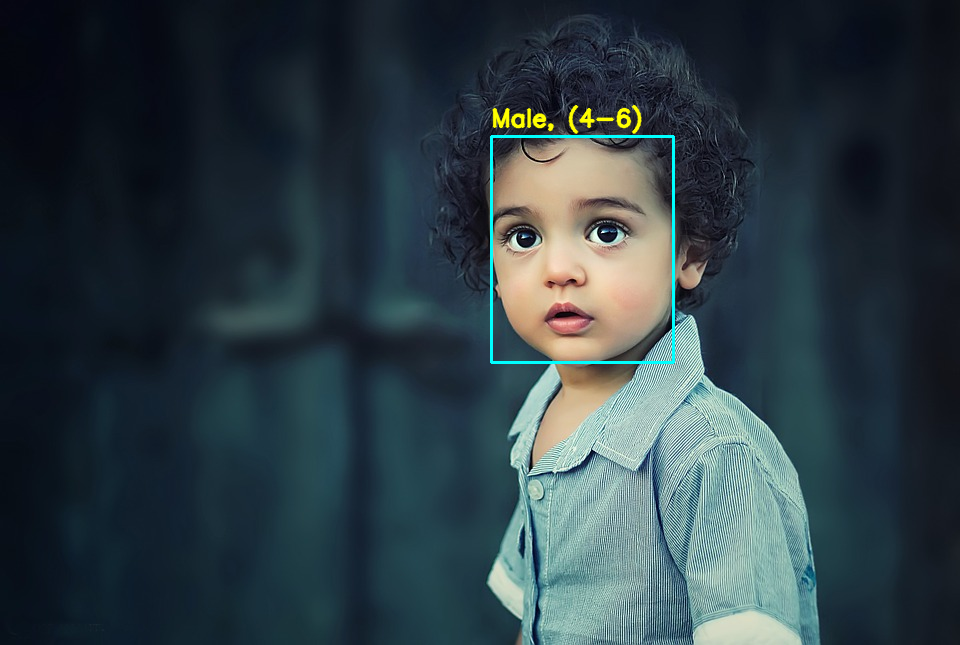

In [52]:
predict("kid1.jpg")


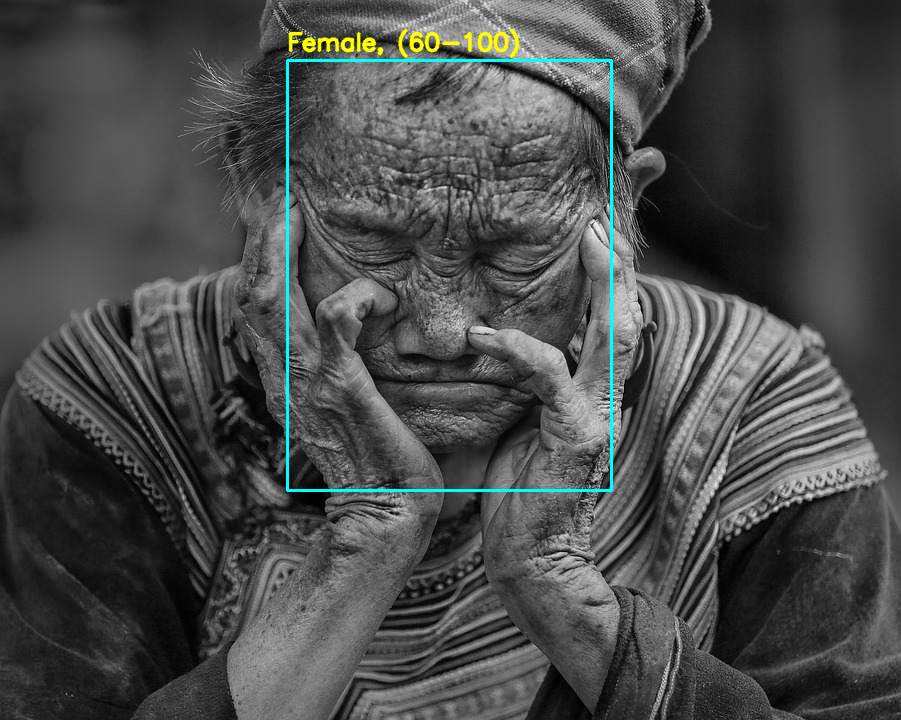

In [54]:
predict("man1.jpg")

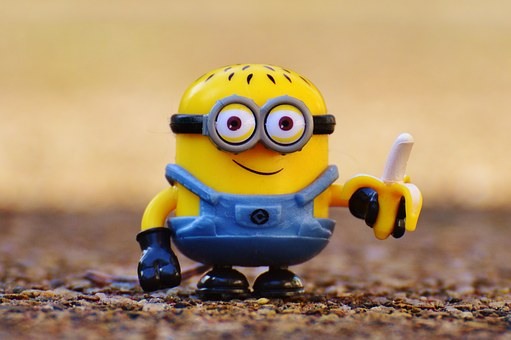

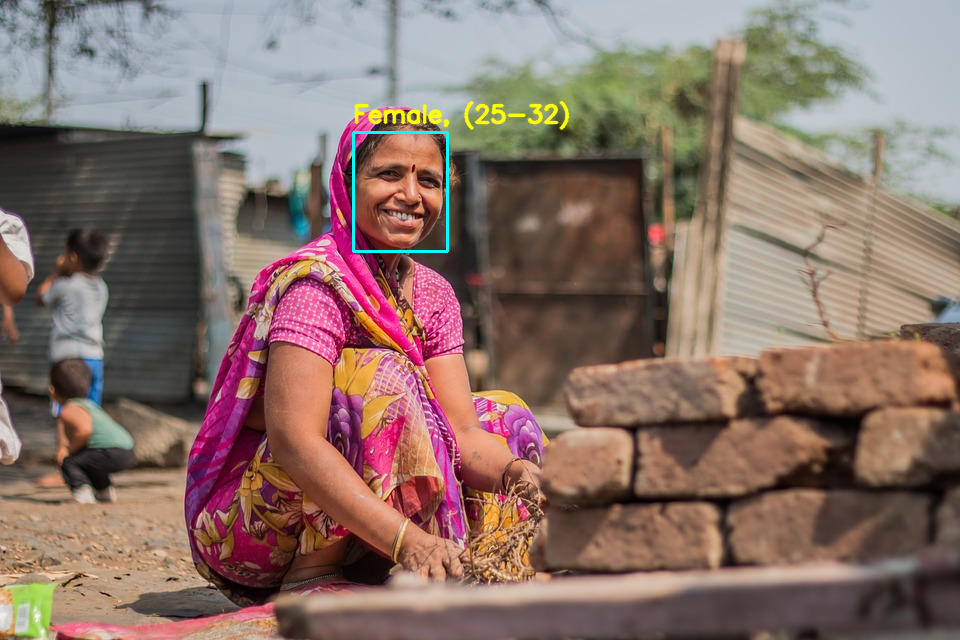

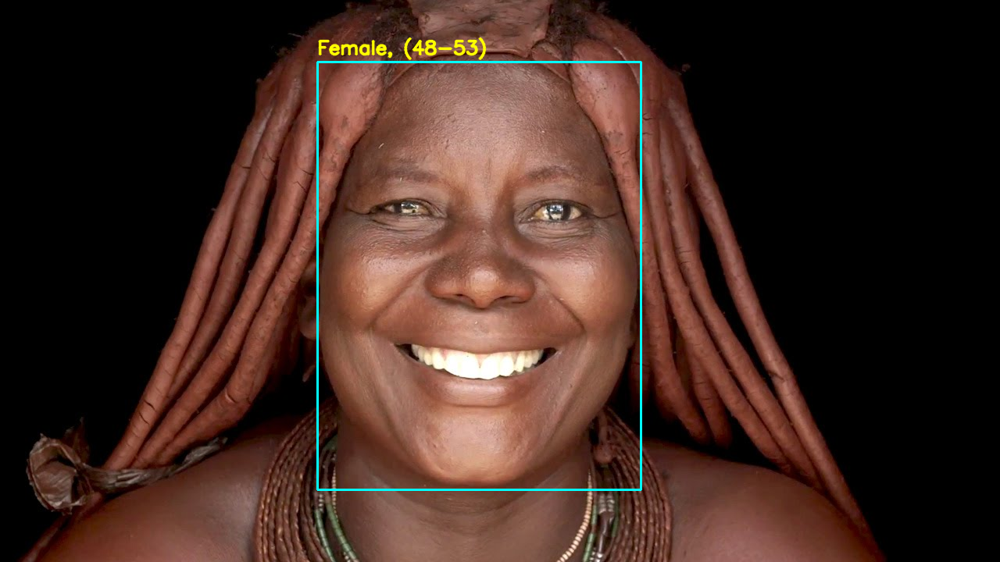

In [55]:
predict("minion.jpg")
predict("woman1.jpg")
predict("woman3.jpg")

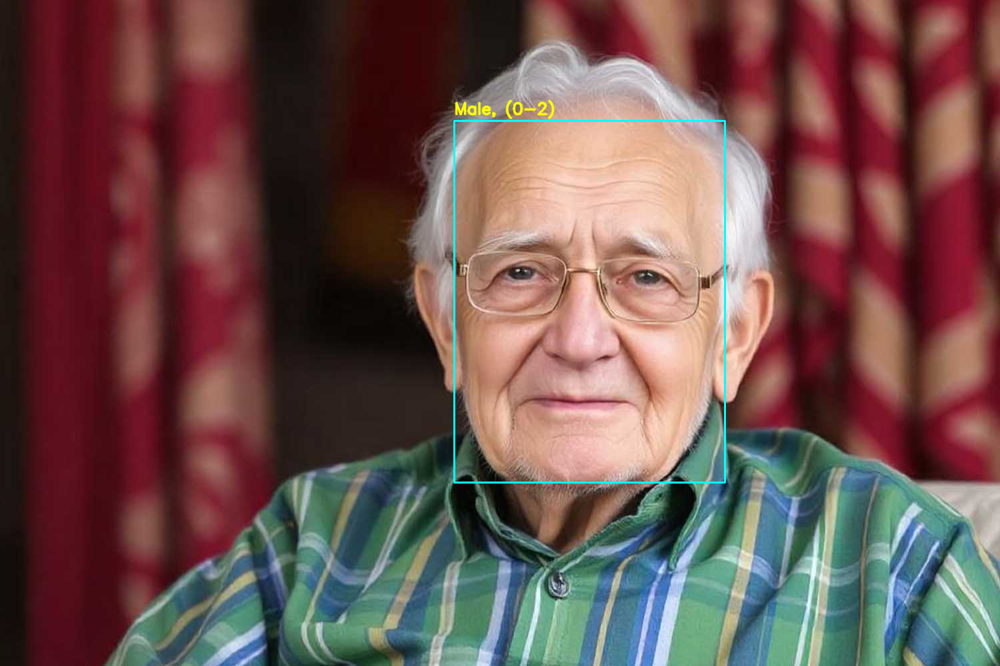

In [56]:
predict("Toching-Grandpa-to-Be-Wishes.jpg")

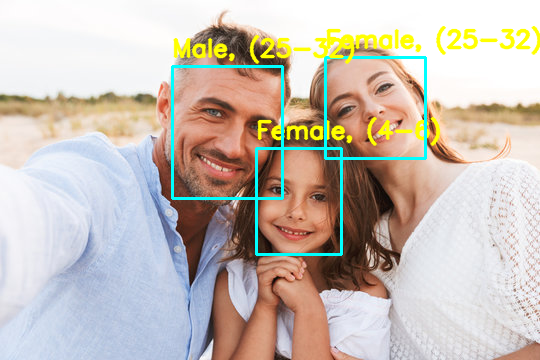

In [59]:
predict("/content/360_F_217130573_lxprwZvm2eTaxR8eZ0AgYLj1e2gIek7F.jpg")